# Semana 1: carga y reporte WA_Crash

En este notebook se construye un flujo completo de trabajo:

1. Configurar la ruta del proyecto para importar las clases reutilizables.
2. Cargar el dataset kalley/WA_Crash desde Hugging Face.
3. Obtener un DataFrame de pandas y revisar su estructura.
4. Verificar el periodo y explorar las variables relevantes para la pregunta analítica.
5. Aplicar transformaciones para el reporte y guardar el resumen en un archivo .txt.
    
Ejecuta las celdas en orden. Si el dataset requiere autenticación, inicia sesión previamente con hf auth login.

# 1. Preparar el entorno e importar la clase de carga

El notebook puede ejecutarse desde distintas carpetas. Por eso se buscan los directorios padres hasta encontrar src/clases_po y se agrega src a sys.path. Así se puede importar HFDatasetLoader sin instalar el proyecto como paquete.

In [1]:
import sys
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd().resolve()
while ROOT != ROOT.parent and not (ROOT / "src" / "clases_po").exists():
    ROOT = ROOT.parent

sys.path.insert(0, str(ROOT / "src"))

from clases_po import HFDatasetLoader, Reportes

/home/runner/work/PI_2026_IUD/PI_2026_IUD/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# 2. Configurar el dataset y la salida

dataset_name identifica el repositorio en Hugging Face y split="train" indica la división que se descargará. El parámetro filename hace que el DataFrame también se guarde como CSV en src/sincronicas/datos/ cuando el notebook se ejecuta desde esa carpeta.

In [2]:
hfdataset = HFDatasetLoader(
    dataset_name = "kalley/WA_Crash",
    split = "train",
    filename = "datos/WA_Crashn.csv"
)

# 3. Descargar el dataset y crear el DataFrame

El método load() descarga el dataset, lo convierte a pandas.DataFrame y lo asigna a la variable df. La expresión df.head() muestra las primeras filas para comprobar que la carga fue exitosa.

In [3]:
df = hfdataset.load()

Generating train split:   0%|          | 0/127102 [00:00<?, ? examples/s]

Generating train split:  39%|███▉      | 50000/127102 [00:00<00:00, 405202.13 examples/s]

Generating train split:  87%|████████▋ | 110000/127102 [00:00<00:00, 444082.15 examples/s]

Generating train split: 100%|██████████| 127102/127102 [00:00<00:00, 438142.69 examples/s]

In [4]:
df.head(5)

,X,Y,ACC_ID,ROAD_NO,ROAD_NAME,COMMON_ROAD_NAME,CWAY,SLK,INTERSECTION_NO,INTERSECTION_DESC,...,EVENT_NATURE,EVENT_TYPE,TOTAL_BIKE_INVOLVED,TOTAL_TRUCK_INVOLVED,TOTAL_HEAVY_TRUCK_INVOLVED,TOTAL_MOTOR_CYCLE_INVOLVED,TOTAL_OTHER_VEHICLES_INVOLVED,TOTAL_PEDESTRIANS_INVOLVED,OBJECTID,GlobalID
0,115.907761,-31.966608,10972646,1290190,Cookham Rd,Cookham Rd,S,0.76,NaN,None,...,Rear End,Involving Parking,0,0,0,0,2,0,53073718,{DFA6DABF-C7F2-429F-A9FA-4E7D332F5320}
1,115.789670,-32.145711,10972652,H002,Melville Mandurah Hwy,Rockingham Rd,L,11.15,13935.0,Melville Mandurah Hwy & Cockburn Rd,...,Rear End,None,0,0,1,0,1,0,53073719,{025E0A45-51FE-48CB-AC07-CF059C72A92E}
2,115.980692,-31.993529,10972658,H018,Roe Hwy,Roe Hwy,L,27.78,NaN,None,...,Rear End,None,0,0,1,0,1,0,53073720,{776D4032-F18E-4FCE-8D9C-54A47649A164}
3,115.808775,-31.777105,10972671,H035,Wanneroo Rd,Wanneroo Rd,L,18.92,11972.0,Wanneroo Rd & East Rd,...,Rear End,None,0,0,0,0,2,0,53073721,{2203115F-5D82-454E-9700-9789BCF0A953}
4,115.741921,-31.826004,10972687,1318348,Southside Dr,Southside Dr,S,0.51,NaN,None,...,None,None,0,0,0,0,2,0,53073722,{769836B0-91DB-4477-9EA4-8498B75FEEFB}


# 4. Revisar la estructura del DataFrame

Esta celda realiza una revisión inicial: cuenta filas y columnas y muestra el tipo de cada columna junto con información de memoria y valores no nulos. Esta inspección ayuda a detectar problemas antes de analizar los datos.

In [5]:
print(f"Filas: {len(df)}")
print(f"Columnas: {len(df.columns)}")
df.info()

Filas: 127102
Columnas: 26
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 127102 entries, 0 to 127101
Data columns (total 26 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   X                              127102 non-null  float64
 1   Y                              127102 non-null  float64
 2   ACC_ID                         127102 non-null  int64  
 3   ROAD_NO                        127102 non-null  object 
 4   ROAD_NAME                      127102 non-null  object 
 5   COMMON_ROAD_NAME               127102 non-null  object 
 6   CWAY                           127102 non-null  object 
 7   SLK                            127102 non-null  float64
 8   INTERSECTION_NO                68123 non-null   float64
 9   INTERSECTION_DESC              68123 non-null   object 
 10  LONGITUDE                      127102 non-null  float64
 11  LATITUDE                       127102 non-null  float64
 12  CRA

## 4.1 Verificar la cobertura del periodo analítico

La pregunta analiza accidentes entre 2019 y 2023. Primero se interpreta `CRASH_DATE` como fecha y se comprueba que el dataset cubra todos esos años.

In [6]:
fechas = pd.to_datetime(df["CRASH_DATE"], dayfirst=True, errors="coerce")

print("Fechas interpretables:", fechas.notna().sum())
print("Fechas no interpretables:", fechas.isna().sum())
print("Fecha mínima:", fechas.min())
print("Fecha máxima:", fechas.max())

conteo_por_anio = (
    fechas.dt.year.value_counts()
    .sort_index()
    .reindex(range(2019, 2024), fill_value=0)
)

print("\nAccidentes por año entre 2019 y 2023:")
print(conteo_por_anio)

Fechas interpretables: 127102
Fechas no interpretables: 0
Fecha mínima: 2019-01-01 00:00:00
Fecha máxima: 2023-12-31 00:00:00

Accidentes por año entre 2019 y 2023:
CRASH_DATE
2019    26685
2020    22975
2021    26566
2022    25057
2023    25819
Name: count, dtype: int64


## 4.2 Explorar las variables de la pregunta analítica

Antes de transformar los datos, se revisan las categorías y los valores faltantes de severidad, tipo de calzada, intersección, hora y conteos de vehículos involucrados.

In [7]:
for columna in [
    "SEVERITY",
    "CWAY",
    "INTERSECTION_NO",
    "INTERSECTION_DESC",
    "CRASH_TIME",
    "TOTAL_BIKE_INVOLVED",
    "TOTAL_TRUCK_INVOLVED",
    "TOTAL_HEAVY_TRUCK_INVOLVED",
    "TOTAL_MOTOR_CYCLE_INVOLVED",
    "TOTAL_OTHER_VEHICLES_INVOLVED",
    "TOTAL_PEDESTRIANS_INVOLVED",
]:
    print(f"\n--- {columna} ---")
    print(df[columna].value_counts(dropna=False).head(20))


--- SEVERITY ---
SEVERITY
PDO Major    68868
PDO Minor    34750
Medical      16485
Hospital      6264
Fatal          735
Name: count, dtype: int64

--- CWAY ---
CWAY
S    69954
L    44758
R    12390
Name: count, dtype: int64

--- INTERSECTION_NO ---
INTERSECTION_NO
NaN         58979
3717.0        263
228503.0      261
43729.0       214
4547.0        163
50705.0       161
43737.0       156
4255.0        151
4147.0        150
90889.0       150
41086.0       142
47055.0       141
14827.0       140
77885.0       128
55048.0       128
235970.0      124
56046.0       124
4154.0        120
13791.0       120
137008.0      119
Name: count, dtype: int64

--- INTERSECTION_DESC ---
INTERSECTION_DESC
None                                                                                                         58979
Reid Hwy & Erindale Rd                                                                                         263
Mitchell Fwy (Northbound) off to Hester Av & Hester Av                  

## 4.3 Preparar los datos para la pregunta analítica

Se trabaja sobre una copia y se limita el análisis al periodo solicitado, sin modificar el DataFrame original.

In [8]:
df_analisis = df.copy()

df_analisis["CRASH_DATE"] = pd.to_datetime(
    df_analisis["CRASH_DATE"],
    dayfirst=True,
    errors="coerce"
)

df_analisis = df_analisis[
    df_analisis["CRASH_DATE"].dt.year.between(2019, 2023)
].copy()

print("Filas para el análisis:", len(df_analisis))
print("Fecha inicial:", df_analisis["CRASH_DATE"].min())
print("Fecha final:", df_analisis["CRASH_DATE"].max())
print("\nAccidentes por año:")
print(df_analisis["CRASH_DATE"].dt.year.value_counts().sort_index())

Filas para el análisis: 127102
Fecha inicial: 2019-01-01 00:00:00
Fecha final: 2023-12-31 00:00:00

Accidentes por año:
CRASH_DATE
2019    26685
2020    22975
2021    26566
2022    25057
2023    25819
Name: count, dtype: int64


## 4.4 Revisar valores faltantes en las variables relevantes

In [9]:
columnas_analisis = [
    "SEVERITY",
    "CWAY",
    "INTERSECTION_NO",
    "INTERSECTION_DESC",
    "CRASH_TIME",
    "TOTAL_BIKE_INVOLVED",
    "TOTAL_TRUCK_INVOLVED",
    "TOTAL_HEAVY_TRUCK_INVOLVED",
    "TOTAL_MOTOR_CYCLE_INVOLVED",
    "TOTAL_OTHER_VEHICLES_INVOLVED",
    "TOTAL_PEDESTRIANS_INVOLVED",
]

for columna in columnas_analisis:
    nulos = df_analisis[columna].isna().sum()
    porcentaje = nulos / len(df_analisis) * 100

    print(f"{columna}: {nulos} valores faltantes ({porcentaje:.2f}%)")

SEVERITY: 0 valores faltantes (0.00%)
CWAY: 0 valores faltantes (0.00%)
INTERSECTION_NO: 58979 valores faltantes (46.40%)
INTERSECTION_DESC: 58979 valores faltantes (46.40%)
CRASH_TIME: 109 valores faltantes (0.09%)
TOTAL_BIKE_INVOLVED: 0 valores faltantes (0.00%)
TOTAL_TRUCK_INVOLVED: 0 valores faltantes (0.00%)
TOTAL_HEAVY_TRUCK_INVOLVED: 0 valores faltantes (0.00%)
TOTAL_MOTOR_CYCLE_INVOLVED: 0 valores faltantes (0.00%)
TOTAL_OTHER_VEHICLES_INVOLVED: 0 valores faltantes (0.00%)
TOTAL_PEDESTRIANS_INVOLVED: 0 valores faltantes (0.00%)


## 4.5 Verificar la consistencia de los datos de intersección

Se comprueba si el identificador y la descripción de intersección tienen faltantes en los mismos registros.

In [10]:
tabla_interseccion = pd.crosstab(
    df_analisis["INTERSECTION_NO"].notna(),
    df_analisis["INTERSECTION_DESC"].notna(),
    rownames=["INTERSECTION_NO informado"],
    colnames=["INTERSECTION_DESC informada"],
    margins=True
)

print(tabla_interseccion)

print("\nDescripciones de intersección más frecuentes:")
print(df_analisis["INTERSECTION_DESC"].value_counts(dropna=False).head(10))

INTERSECTION_DESC informada  False   True     All
INTERSECTION_NO informado                        
False                        58979      0   58979
True                             0  68123   68123
All                          58979  68123  127102

Descripciones de intersección más frecuentes:
INTERSECTION_DESC
None                                                            58979
Reid Hwy & Erindale Rd                                            263
Mitchell Fwy (Northbound) off to Hester Av & Hester Av            261
Nicholson Rd & Garden St & Yale Rd                                214
Tonkin Hwy & Rivervale Wattle Grove Link & Welshpool Rd East      163
Thomas St & Loftus St & Railway St & Railway Pde & Loftus St      161
Nicholson Rd & Ranford Rd & Nicholson Rd & Ranford Rd             156
Albany Hwy & Nicholson Rd & Nicholson Rd                          151
Great Northern Hwy & Roe Hwy & Reid Hwy & Great Northern Hwy      150
Mirrabooka Av & Hepburn Av                             

## 4.6 Validar la hora y crear franjas horarias

Primero se comprueba el formato HHMM; luego se agrupan las horas válidas. Los datos faltantes se mantienen como `Sin dato`.

In [11]:
horas = pd.to_numeric(df_analisis["CRASH_TIME"], errors="coerce")

hora_invalida = horas.notna() & (
    (horas < 0)
    | (horas > 2359)
    | (horas % 100 >= 60)
    | (horas % 1 != 0)
)

print("Horas faltantes:", horas.isna().sum())
print("Horas con formato inválido:", hora_invalida.sum())
print("Valores inválidos de ejemplo:")
print(horas[hora_invalida].head(10).tolist())
print("Valores de hora más frecuentes:")
print(horas.value_counts().head(10))

Horas faltantes: 109
Horas con formato inválido: 0
Valores inválidos de ejemplo:
[]
Valores de hora más frecuentes:
CRASH_TIME
1630.0    2149
1530.0    2136
1600.0    1956
1730.0    1892
1700.0    1865
1500.0    1824
1430.0    1580
830.0     1577
1800.0    1509
1230.0    1455
Name: count, dtype: int64


In [12]:
hora_del_dia = horas // 100

df_analisis["FRANJA_HORARIA"] = pd.cut(
    hora_del_dia,
    bins=[-1, 5, 11, 17, 23],
    labels=[
        "Madrugada (00:00-05:59)",
        "Mañana (06:00-11:59)",
        "Tarde (12:00-17:59)",
        "Noche (18:00-23:59)",
    ],
).astype("object").fillna("Sin dato")

print(df_analisis["FRANJA_HORARIA"].value_counts(dropna=False))

FRANJA_HORARIA
Tarde (12:00-17:59)        60278
Mañana (06:00-11:59)       41208
Noche (18:00-23:59)        20152
Madrugada (00:00-05:59)     5355
Sin dato                     109
Name: count, dtype: int64


## 4.7 Distribución de severidad por tipo de calzada

Los códigos se conservan tal como aparecen en el dataset.

In [13]:
conteo_calzada_severidad = pd.crosstab(
    df_analisis["CWAY"],
    df_analisis["SEVERITY"],
    margins=True
)

porcentaje_calzada_severidad = (
    pd.crosstab(
        df_analisis["CWAY"],
        df_analisis["SEVERITY"],
        normalize="index"
    ) * 100
).round(2)

print("Conteos por tipo de calzada:")
print(conteo_calzada_severidad)

print("\nPorcentaje de severidad dentro de cada tipo de calzada:")
print(porcentaje_calzada_severidad)

Conteos por tipo de calzada:
SEVERITY  Fatal  Hospital  Medical  PDO Major  PDO Minor     All
CWAY                                                            
L            96      1645     6844      24205      11968   44758
R            41       483     1721       6769       3376   12390
S           598      4136     7920      37894      19406   69954
All         735      6264    16485      68868      34750  127102

Porcentaje de severidad dentro de cada tipo de calzada:
SEVERITY  Fatal  Hospital  Medical  PDO Major  PDO Minor
CWAY                                                    
L          0.21      3.68    15.29      54.08      26.74
R          0.33      3.90    13.89      54.63      27.25
S          0.85      5.91    11.32      54.17      27.74


## 4.8 Distribución de severidad según registro de intersección

"No registrada" describe la falta de información y no confirma que el accidente ocurriera fuera de una intersección.

In [14]:
df_analisis["ESTADO_INTERSECCION"] = (
    df_analisis["INTERSECTION_DESC"]
    .notna()
    .map({
        True: "Intersección registrada",
        False: "Intersección no registrada",
    })
)

conteo_interseccion_severidad = pd.crosstab(
    df_analisis["ESTADO_INTERSECCION"],
    df_analisis["SEVERITY"],
    margins=True
)

porcentaje_interseccion_severidad = (
    pd.crosstab(
        df_analisis["ESTADO_INTERSECCION"],
        df_analisis["SEVERITY"],
        normalize="index"
    ) * 100
).round(2)

print("Conteos:")
print(conteo_interseccion_severidad)

print("\nPorcentaje de severidad dentro de cada grupo de intersección:")
print(porcentaje_interseccion_severidad)

Conteos:
SEVERITY                    Fatal  Hospital  Medical  PDO Major  PDO Minor  \
ESTADO_INTERSECCION                                                          
Intersección no registrada    581      3531     5995      31591      17281   
Intersección registrada       154      2733    10490      37277      17469   
All                           735      6264    16485      68868      34750   

SEVERITY                       All  
ESTADO_INTERSECCION                 
Intersección no registrada   58979  
Intersección registrada      68123  
All                         127102  

Porcentaje de severidad dentro de cada grupo de intersección:
SEVERITY                    Fatal  Hospital  Medical  PDO Major  PDO Minor
ESTADO_INTERSECCION                                                       
Intersección no registrada   0.99      5.99    10.16      53.56      29.30
Intersección registrada      0.23      4.01    15.40      54.72      25.64


## 4.9 Distribución de severidad por franja horaria

In [15]:
conteo_horario_severidad = pd.crosstab(
    df_analisis["FRANJA_HORARIA"],
    df_analisis["SEVERITY"],
    margins=True
)

porcentaje_horario_severidad = (
    pd.crosstab(
        df_analisis["FRANJA_HORARIA"],
        df_analisis["SEVERITY"],
        normalize="index"
    ) * 100
).round(2)

print("Conteos por franja horaria:")
print(conteo_horario_severidad)

print("\nPorcentaje de severidad dentro de cada franja:")
print(porcentaje_horario_severidad)

Conteos por franja horaria:
SEVERITY                 Fatal  Hospital  Medical  PDO Major  PDO Minor  \
FRANJA_HORARIA                                                            
Madrugada (00:00-05:59)    106       492      486       3023       1248   
Mañana (06:00-11:59)       205      1763     5810      21895      11535   
Noche (18:00-23:59)        180      1415     2165      11033       5359   
Sin dato                     2        14       55          7         31   
Tarde (12:00-17:59)        242      2580     7969      32910      16577   
All                        735      6264    16485      68868      34750   

SEVERITY                    All  
FRANJA_HORARIA                   
Madrugada (00:00-05:59)    5355  
Mañana (06:00-11:59)      41208  
Noche (18:00-23:59)       20152  
Sin dato                    109  
Tarde (12:00-17:59)       60278  
All                      127102  

Porcentaje de severidad dentro de cada franja:
SEVERITY                 Fatal  Hospital  Medical  

## 4.10 Distribución de severidad por tipo de vehículo

Cada tipo se compara por separado; un accidente puede aparecer en más de un grupo.

In [16]:
columnas_vehiculos = {
    "TOTAL_BIKE_INVOLVED": "Bicicleta",
    "TOTAL_TRUCK_INVOLVED": "Camión",
    "TOTAL_HEAVY_TRUCK_INVOLVED": "Camión pesado",
    "TOTAL_MOTOR_CYCLE_INVOLVED": "Motocicleta",
    "TOTAL_OTHER_VEHICLES_INVOLVED": "Otros vehículos",
}

In [17]:
columnas_vehiculos = {
    "TOTAL_BIKE_INVOLVED": "Bicicleta",
    "TOTAL_TRUCK_INVOLVED": "Camión",
    "TOTAL_HEAVY_TRUCK_INVOLVED": "Camión pesado",
    "TOTAL_MOTOR_CYCLE_INVOLVED": "Motocicleta",
    "TOTAL_OTHER_VEHICLES_INVOLVED": "Otros vehículos",
}

severidades = ["Fatal", "Hospital", "Medical", "PDO Major", "PDO Minor"]
resumen_vehiculos = []

for columna, tipo in columnas_vehiculos.items():
    estado = df_analisis[columna].gt(0).map({
        True: "Con " + tipo,
        False: "Sin " + tipo,
    })

    conteos = pd.crosstab(estado, df_analisis["SEVERITY"])
    porcentajes = pd.crosstab(
        estado,
        df_analisis["SEVERITY"],
        normalize="index"
    ) * 100

    for grupo in conteos.index:
        fila = {
            "Tipo de vehículo": tipo,
            "Grupo": grupo,
            "Accidentes": conteos.loc[grupo].sum(),
        }
        fila.update({
            f"{severidad} (%)": round(porcentajes.loc[grupo, severidad], 2)
            for severidad in severidades
        })
        resumen_vehiculos.append(fila)

print(pd.DataFrame(resumen_vehiculos).to_string(index=False))

Tipo de vehículo               Grupo  Accidentes  Fatal (%)  Hospital (%)  Medical (%)  PDO Major (%)  PDO Minor (%)
       Bicicleta       Con Bicicleta        2539       0.55         15.20        23.32           7.37          53.56
       Bicicleta       Sin Bicicleta      124563       0.58          4.72        12.76          55.14          26.81
          Camión          Con Camión        4530       0.95          4.37        10.79          57.95          25.94
          Camión          Sin Camión      122572       0.56          4.95        13.05          54.04          27.39
   Camión pesado   Con Camión pesado        2318       2.24          6.21         8.80          59.32          23.43
   Camión pesado   Sin Camión pesado      124784       0.55          4.90        13.05          54.09          27.41
     Motocicleta     Con Motocicleta        4334       3.65         29.67        13.34          23.40          29.95
     Motocicleta     Sin Motocicleta      122768       0.47     

## 4.11 Gráficas comparativas

Las barras apiladas muestran porcentajes dentro de cada grupo.

### Severidad por tipo de calzada

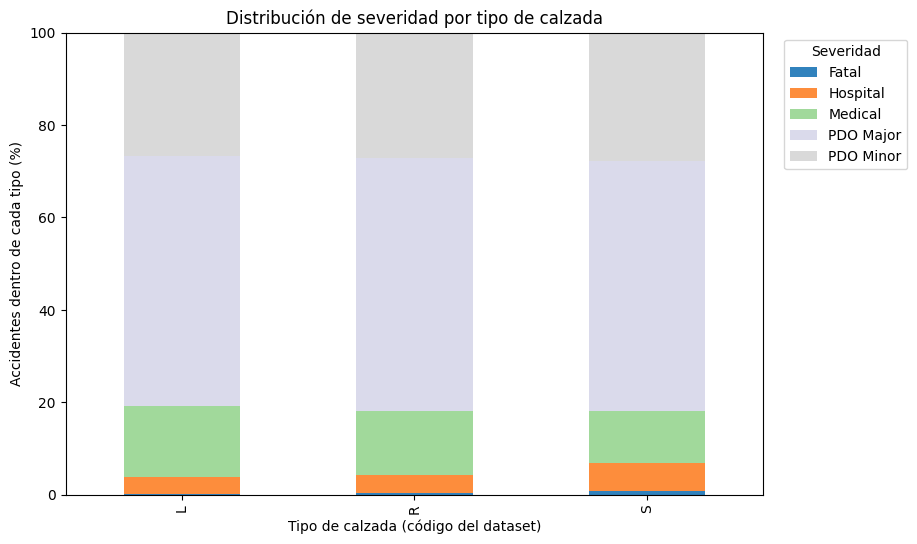

In [18]:
import matplotlib.pyplot as plt

porcentajes_calzada = porcentaje_calzada_severidad.reindex(["L", "R", "S"])

ax = porcentajes_calzada.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 6),
    colormap="tab20c"
)

ax.set_title("Distribución de severidad por tipo de calzada")
ax.set_xlabel("Tipo de calzada (código del dataset)")
ax.set_ylabel("Accidentes dentro de cada tipo (%)")
ax.set_ylim(0, 100)
ax.legend(title="Severidad", bbox_to_anchor=(1.02, 1), loc="upper left")


plt.show()

### Severidad según registro de intersección

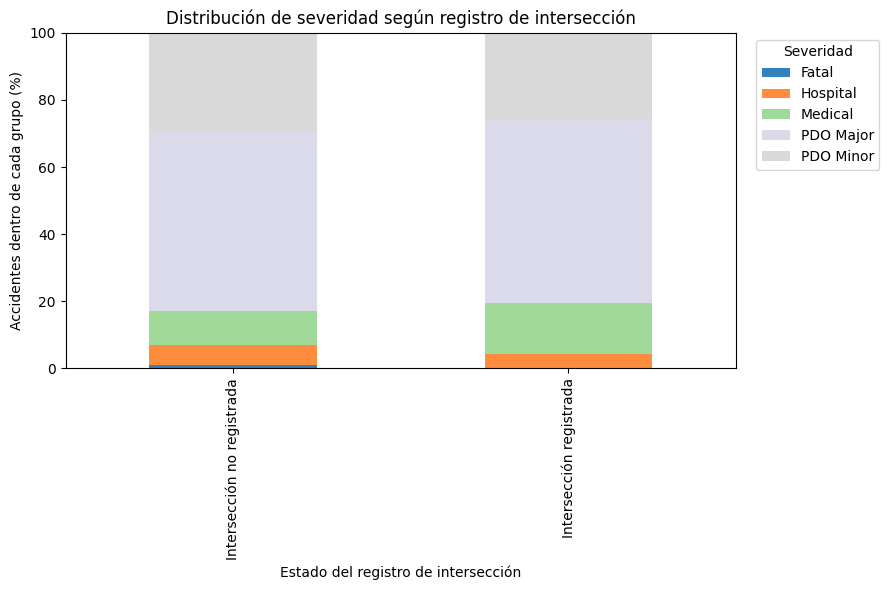

In [19]:
import matplotlib.pyplot as plt

orden_interseccion = [
    "Intersección no registrada",
    "Intersección registrada",
]

porcentajes_interseccion = porcentaje_interseccion_severidad.reindex(
    orden_interseccion
)

ax = porcentajes_interseccion.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 6),
    colormap="tab20c"
)

ax.set_title("Distribución de severidad según registro de intersección")
ax.set_xlabel("Estado del registro de intersección")
ax.set_ylabel("Accidentes dentro de cada grupo (%)")
ax.set_ylim(0, 100)
ax.legend(title="Severidad", bbox_to_anchor=(1.02, 1), loc="upper left")

plt.tight_layout()
plt.show()

### Severidad por franja horaria

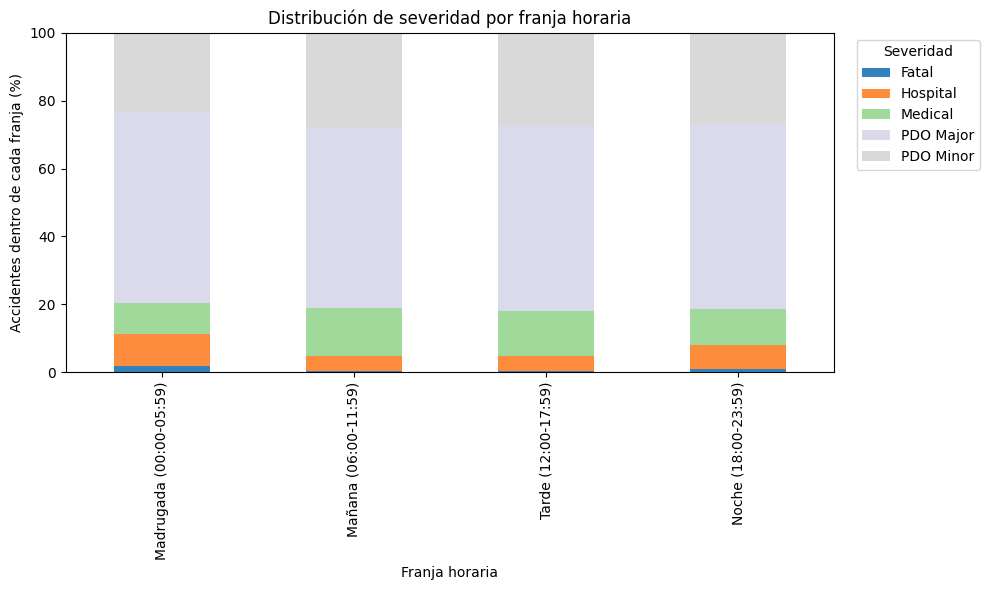

In [20]:
import matplotlib.pyplot as plt

orden_franjas = [
    "Madrugada (00:00-05:59)",
    "Mañana (06:00-11:59)",
    "Tarde (12:00-17:59)",
    "Noche (18:00-23:59)",
]

porcentajes_horario_conocido = porcentaje_horario_severidad.reindex(
    orden_franjas
)

ax = porcentajes_horario_conocido.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 6),
    colormap="tab20c"
)

ax.set_title("Distribución de severidad por franja horaria")
ax.set_xlabel("Franja horaria")
ax.set_ylabel("Accidentes dentro de cada franja (%)")
ax.set_ylim(0, 100)
ax.legend(title="Severidad", bbox_to_anchor=(1.02, 1), loc="upper left")

plt.tight_layout()
plt.show()

### Severidad por tipo de vehículo

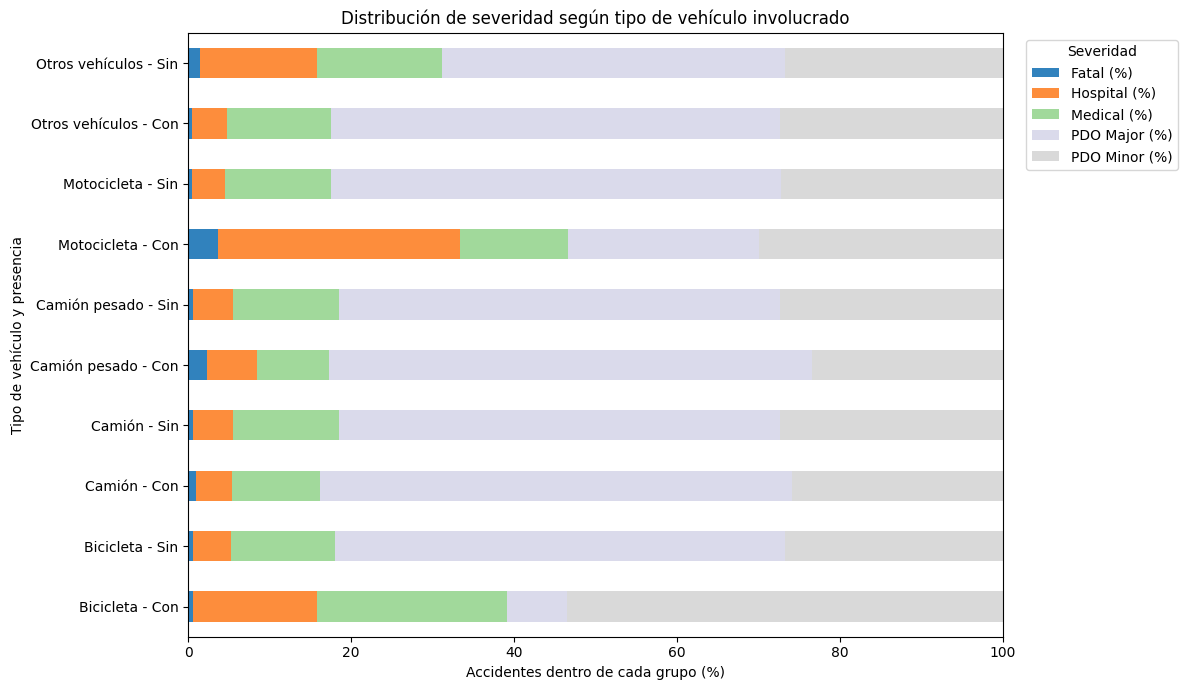

In [21]:
import matplotlib.pyplot as plt

tabla_grafica = pd.DataFrame(resumen_vehiculos)

tabla_grafica["Estado"] = tabla_grafica["Grupo"].str.split().str[0]
tabla_grafica["Etiqueta"] = (
    tabla_grafica["Tipo de vehículo"] + " - " + tabla_grafica["Estado"]
)

columnas_porcentajes = [
    "Fatal (%)",
    "Hospital (%)",
    "Medical (%)",
    "PDO Major (%)",
    "PDO Minor (%)",
]

datos_grafica = tabla_grafica.set_index("Etiqueta")[columnas_porcentajes]

ax = datos_grafica.plot(
    kind="barh",
    stacked=True,
    figsize=(12, 7),
    colormap="tab20c"
)

ax.set_title("Distribución de severidad según tipo de vehículo involucrado")
ax.set_xlabel("Accidentes dentro de cada grupo (%)")
ax.set_ylabel("Tipo de vehículo y presencia")
ax.set_xlim(0, 100)
ax.legend(
    title="Severidad",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

## Interpretación preliminar

El análisis considera 127.102 accidentes registrados entre el 1 de enero de 2019 y el 31 de diciembre de 2023. Las tablas y gráficas muestran la distribución porcentual de las categorías de severidad dentro de cada grupo comparado.

### Franja horaria

La categoría `PDO Major` fue la más frecuente en todas las franjas horarias. La proporción de accidentes clasificados como `Fatal` fue mayor en la madrugada (1,98 %) que en la noche (0,89 %), la mañana (0,50 %) y la tarde (0,40 %). Los 109 registros sin hora se conservaron como “Sin dato” y no se asignaron a una franja.

### Tipo de calzada

`PDO Major` también fue la categoría más frecuente para los tres códigos de calzada. La proporción de accidentes `Fatal` fue de 0,85 % en `S`, 0,33 % en `R` y 0,21 % en `L`. En este análisis se mantienen los códigos tal como aparecen en el dataset; no se les asigna un significado sin verificarlo en la fuente.

### Registro de intersección

En 68.123 accidentes la intersección estaba registrada y en 58.979 no estaba registrada. La proporción de accidentes `Fatal` fue de 0,23 % en el grupo con intersección registrada y de 0,99 % en el grupo sin registro. La ausencia de información no permite concluir que el accidente haya ocurrido fuera de una intersección.

### Tipos de vehículos involucrados

Las proporciones de las categorías `Fatal` y `Hospital` fueron mayores en los accidentes con motocicleta (3,65 % y 29,67 %, respectivamente) que en los accidentes sin motocicleta (0,47 % y 4,05 %). También se observó una proporción `Fatal` mayor en los accidentes con camión pesado (2,24 %) que en aquellos sin camión pesado (0,55 %).

Cada tipo de vehículo se analizó por separado. Por ello, los grupos no son excluyentes: un mismo accidente puede involucrar más de un tipo de vehículo. Las comparaciones son descriptivas y no demuestran que el tipo de vehículo, la franja horaria, la calzada o el registro de intersección causen una determinada severidad.

# 5. Transformaciones para el reporte

Estas transformaciones se aplican a un DataFrame separado para cumplir el ejercicio de preparación y reporte. No reemplazan ni filtran `df_analisis`, que conserva todos los accidentes del periodo para responder la pregunta analítica.

# Transformación 1: Filtrar los accidentes Rear End

Para cumplir el ejercicio de transformación, el DataFrame destinado al reporte se filtra por `EVENT_NATURE == "Rear End"`. Este filtro se usa solo en el reporte de transformaciones; `df_analisis` conserva todos los accidentes de 2019 a 2023 para responder la pregunta analítica.

In [22]:
df_transformado = df.copy()
dt_filtrado = df_transformado[
    df_transformado["EVENT_NATURE"] == "Rear End"
].copy()

print("Accidentes Rear End para el reporte:", len(dt_filtrado))
dt_filtrado.head()

Accidentes Rear End para el reporte: 52656


,X,Y,ACC_ID,ROAD_NO,ROAD_NAME,COMMON_ROAD_NAME,CWAY,SLK,INTERSECTION_NO,INTERSECTION_DESC,...,EVENT_NATURE,EVENT_TYPE,TOTAL_BIKE_INVOLVED,TOTAL_TRUCK_INVOLVED,TOTAL_HEAVY_TRUCK_INVOLVED,TOTAL_MOTOR_CYCLE_INVOLVED,TOTAL_OTHER_VEHICLES_INVOLVED,TOTAL_PEDESTRIANS_INVOLVED,OBJECTID,GlobalID
0,115.907761,-31.966608,10972646,1290190,Cookham Rd,Cookham Rd,S,0.76,NaN,None,...,Rear End,Involving Parking,0,0,0,0,2,0,53073718,{DFA6DABF-C7F2-429F-A9FA-4E7D332F5320}
1,115.789670,-32.145711,10972652,H002,Melville Mandurah Hwy,Rockingham Rd,L,11.15,13935.0,Melville Mandurah Hwy & Cockburn Rd,...,Rear End,None,0,0,1,0,1,0,53073719,{025E0A45-51FE-48CB-AC07-CF059C72A92E}
2,115.980692,-31.993529,10972658,H018,Roe Hwy,Roe Hwy,L,27.78,NaN,None,...,Rear End,None,0,0,1,0,1,0,53073720,{776D4032-F18E-4FCE-8D9C-54A47649A164}
3,115.808775,-31.777105,10972671,H035,Wanneroo Rd,Wanneroo Rd,L,18.92,11972.0,Wanneroo Rd & East Rd,...,Rear End,None,0,0,0,0,2,0,53073721,{2203115F-5D82-454E-9700-9789BCF0A953}
5,116.031149,-31.670670,10972693,H006,Great Northern Hwy,Great Northern Hwy,S,25.43,NaN,None,...,Rear End,None,0,0,0,0,2,0,53073723,{67ABE5F0-D3C6-4D32-9906-4B873F051EA3}


# Transformación 2: Eliminar columnas de coordenadas duplicadas

Se eliminan `X` y `Y` del DataFrame filtrado porque la información geográfica también está representada por `LONGITUDE` y `LATITUDE`.

In [23]:
df_filtrado = dt_filtrado.drop(columns=["X", "Y"]).copy()

print("Dimensiones despues de eliminar X e Y:", df_filtrado.shape)
df_filtrado.head()

Dimensiones despues de eliminar X e Y: (52656, 24)


,ACC_ID,ROAD_NO,ROAD_NAME,COMMON_ROAD_NAME,CWAY,SLK,INTERSECTION_NO,INTERSECTION_DESC,LONGITUDE,LATITUDE,...,EVENT_NATURE,EVENT_TYPE,TOTAL_BIKE_INVOLVED,TOTAL_TRUCK_INVOLVED,TOTAL_HEAVY_TRUCK_INVOLVED,TOTAL_MOTOR_CYCLE_INVOLVED,TOTAL_OTHER_VEHICLES_INVOLVED,TOTAL_PEDESTRIANS_INVOLVED,OBJECTID,GlobalID
0,10972646,1290190,Cookham Rd,Cookham Rd,S,0.76,NaN,None,115.907761,-31.966608,...,Rear End,Involving Parking,0,0,0,0,2,0,53073718,{DFA6DABF-C7F2-429F-A9FA-4E7D332F5320}
1,10972652,H002,Melville Mandurah Hwy,Rockingham Rd,L,11.15,13935.0,Melville Mandurah Hwy & Cockburn Rd,115.789670,-32.145711,...,Rear End,None,0,0,1,0,1,0,53073719,{025E0A45-51FE-48CB-AC07-CF059C72A92E}
2,10972658,H018,Roe Hwy,Roe Hwy,L,27.78,NaN,None,115.980692,-31.993529,...,Rear End,None,0,0,1,0,1,0,53073720,{776D4032-F18E-4FCE-8D9C-54A47649A164}
3,10972671,H035,Wanneroo Rd,Wanneroo Rd,L,18.92,11972.0,Wanneroo Rd & East Rd,115.808775,-31.777105,...,Rear End,None,0,0,0,0,2,0,53073721,{2203115F-5D82-454E-9700-9789BCF0A953}
5,10972693,H006,Great Northern Hwy,Great Northern Hwy,S,25.43,NaN,None,116.031149,-31.670670,...,Rear End,None,0,0,0,0,2,0,53073723,{67ABE5F0-D3C6-4D32-9906-4B873F051EA3}


# Transformación 3: Tratar los valores faltantes

En `EVENT_NATURE` y `EVENT_TYPE`, los valores faltantes se identifican como `"Sin dato"`. `CRASH_TIME` se conserva faltante: no se reemplaza por el promedio porque sus valores tienen formato HHMM y ese promedio no representa una hora válida. También se conservan los faltantes de intersección, ya que no se debe asumir que significan que no había intersección.

In [24]:
for columna in ["EVENT_NATURE", "EVENT_TYPE"]:
    df_filtrado[columna] = df_filtrado[columna].fillna("Sin dato")

print("Valores faltantes despues del tratamiento:")
print(df_filtrado[[
    "CRASH_TIME",
    "EVENT_NATURE",
    "EVENT_TYPE",
    "INTERSECTION_NO",
    "INTERSECTION_DESC",
]].isna().sum())

Valores faltantes despues del tratamiento:
CRASH_TIME              37
EVENT_NATURE             0
EVENT_TYPE               0
INTERSECTION_NO      21074
INTERSECTION_DESC    21074
dtype: int64


# Transformación 4: Renombrar columnas

Se cambian `CWAY` y `SLK` por nombres más descriptivos para el DataFrame del reporte.

In [25]:
df_filtrado = df_filtrado.rename(
    columns={
        "CWAY": "CARRIAGEWAY",
        "SLK": "STRAIGHT_LINE_KILOMETRE",
    }
)

print(f"Dimensiones del DataFrame transformado: {df_filtrado.shape[0]} filas x {df_filtrado.shape[1]} columnas")
df_filtrado.head()

Dimensiones del DataFrame transformado: 52656 filas x 24 columnas


,ACC_ID,ROAD_NO,ROAD_NAME,COMMON_ROAD_NAME,CARRIAGEWAY,STRAIGHT_LINE_KILOMETRE,INTERSECTION_NO,INTERSECTION_DESC,LONGITUDE,LATITUDE,...,EVENT_NATURE,EVENT_TYPE,TOTAL_BIKE_INVOLVED,TOTAL_TRUCK_INVOLVED,TOTAL_HEAVY_TRUCK_INVOLVED,TOTAL_MOTOR_CYCLE_INVOLVED,TOTAL_OTHER_VEHICLES_INVOLVED,TOTAL_PEDESTRIANS_INVOLVED,OBJECTID,GlobalID
0,10972646,1290190,Cookham Rd,Cookham Rd,S,0.76,NaN,None,115.907761,-31.966608,...,Rear End,Involving Parking,0,0,0,0,2,0,53073718,{DFA6DABF-C7F2-429F-A9FA-4E7D332F5320}
1,10972652,H002,Melville Mandurah Hwy,Rockingham Rd,L,11.15,13935.0,Melville Mandurah Hwy & Cockburn Rd,115.789670,-32.145711,...,Rear End,Sin dato,0,0,1,0,1,0,53073719,{025E0A45-51FE-48CB-AC07-CF059C72A92E}
2,10972658,H018,Roe Hwy,Roe Hwy,L,27.78,NaN,None,115.980692,-31.993529,...,Rear End,Sin dato,0,0,1,0,1,0,53073720,{776D4032-F18E-4FCE-8D9C-54A47649A164}
3,10972671,H035,Wanneroo Rd,Wanneroo Rd,L,18.92,11972.0,Wanneroo Rd & East Rd,115.808775,-31.777105,...,Rear End,Sin dato,0,0,0,0,2,0,53073721,{2203115F-5D82-454E-9700-9789BCF0A953}
5,10972693,H006,Great Northern Hwy,Great Northern Hwy,S,25.43,NaN,None,116.031149,-31.670670,...,Rear End,Sin dato,0,0,0,0,2,0,53073723,{67ABE5F0-D3C6-4D32-9906-4B873F051EA3}


In [26]:
from  clases_po import Reportes

# 6. Generar el resumen del DataFrame transformado

La clase `Reportes` resume el DataFrame filtrado y transformado: dimensiones, tipos de columnas, valores faltantes y estadísticas numéricas.

In [27]:
reportes = Reportes()
texto = reportes.generar_reporte(df_filtrado)

print(texto)

REPORTE DEL DATAFRAME
Filas: 52656
Columnas: 24
Duplicados: 0

Columnas y tipos:
- ACC_ID: int64
- ROAD_NO: object
- ROAD_NAME: object
- COMMON_ROAD_NAME: object
- CARRIAGEWAY: object
- STRAIGHT_LINE_KILOMETRE: float64
- INTERSECTION_NO: float64
- INTERSECTION_DESC: object
- LONGITUDE: float64
- LATITUDE: float64
- CRASH_DATE: object
- CRASH_TIME: float64
- ACCIDENT_TYPE: object
- SEVERITY: object
- EVENT_NATURE: object
- EVENT_TYPE: object
- TOTAL_BIKE_INVOLVED: int64
- TOTAL_TRUCK_INVOLVED: int64
- TOTAL_HEAVY_TRUCK_INVOLVED: int64
- TOTAL_MOTOR_CYCLE_INVOLVED: int64
- TOTAL_OTHER_VEHICLES_INVOLVED: int64
- TOTAL_PEDESTRIANS_INVOLVED: int64
- OBJECTID: int64
- GlobalID: object

Valores nulos por columna:
- ACC_ID: 0
- ROAD_NO: 0
- ROAD_NAME: 0
- COMMON_ROAD_NAME: 0
- CARRIAGEWAY: 0
- STRAIGHT_LINE_KILOMETRE: 0
- INTERSECTION_NO: 21074
- INTERSECTION_DESC: 21074
- LONGITUDE: 0
- LATITUDE: 0
- CRASH_DATE: 0
- CRASH_TIME: 37
- ACCIDENT_TYPE: 0
- SEVERITY: 0
- EVENT_NATURE: 0
- EVENT_TYP

# 7. Guardar el resumen en un archivo .txt

El reporte actualizado del DataFrame transformado se guarda en `src/sincronicas/reportes/WA_Crash.txt`, independientemente de la carpeta de trabajo del notebook.

In [28]:
ruta = reportes.guardar_reporte(
    df_filtrado,
    ROOT / "src" / "sincronicas" / "reportes" / "WA_Crash.txt",
)

print(f"Reporte guardado en: {ruta}")

Reporte guardado en: /home/runner/work/PI_2026_IUD/PI_2026_IUD/src/sincronicas/reportes/WA_Crash.txt
